# pyMPPost: collision file → light output

Runs pyMPPost on the collision file written by `../1_write_collision.ipynb` and analyses its output.

pyMPPost can be downloaded from: https://gitlab.eecs.umich.edu/umich-dnng/pymppost

The pyMPPost input files (`input_config.toml` and the material cards) are external and edited by hand.
This notebook reads them to know the collision file, the output location, the number of source
particles (`NPS`) and the detector cells, so that information is written in one place only.

pyMPPost will run within the `gmm_env` environment

In [1]:
import os
import time
import tomli as tomllib
import subprocess

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ================================ CONFIGURATION ================================
PARTICLE = "neutron"                  # "neutron" | "photon" (must match the collision file)

# Folder with the pyMPPost TOML files. pyMPPost is run from here, so relative
# paths inside the TOML files (material cards, output_root) are resolved from it.
MPPOST_DIR   = "./"
INPUT_CONFIG = "input_config.toml"    # e.g. a different file per case / particle

RUN_PYMPPOST = True                   # False: only analyse an existing pyMPPost output
PYMPPOST_EXE = "pyMPPost"             # command used to launch pyMPPost

# Columns of the _All_Pulses file (0-based, negative = from the end)
COL_CELL, COL_PTYPE, COL_LO = 1, 3, -1

# Light output histogram
N_BINS        = 50
LO_MIN        = 0.05                   # [MeVee]
LO_MAX        = 5                  # [MeVee]; None = pulse_height.threshold.upper
PER_BIN_WIDTH = False                 # True: counts per source particle per MeVee

# Results
LABEL    = "OpenMC"                   # prefix of the saved keys, e.g. "OpenMC-bin-edges"
SAVE_DIR = "/Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/helium4/252Cf"
# ===============================================================================

PARTICLE_CODES = {"neutron": 1, "photon": 2}   # MCNPX-PoliMi / pyMPPost particle types
PTYPE = PARTICLE_CODES[PARTICLE]

def resolve(path):
    """Resolve a path from the TOML files relative to MPPOST_DIR."""
    return os.path.normpath(os.path.join(MPPOST_DIR, os.path.expanduser(path)))

# --- Read the pyMPPost input file ---------------------------------------------
config_path = resolve(INPUT_CONFIG)
with open(config_path, "rb") as f:
    CFG = tomllib.load(f)

COLLISION_FILE = resolve(CFG["i/o"]["polimi_det_in"])
OUTPUT_ROOT    = resolve(CFG["i/o"]["output_root"])
HAS_HEADER     = CFG["i/o"].get("output_headers", True)
NPS            = int(CFG["detectors"]["NPS"])
DETECTOR_CELLS = CFG["detectors"]["detector_cells"]
LO_THRESHOLD   = (CFG["pulse_height"]["threshold"]["lower"],
                  CFG["pulse_height"]["threshold"]["upper"])
ALL_PULSES     = f"{OUTPUT_ROOT}_All_Pulses"

if LO_MAX is None:
    LO_MAX = LO_THRESHOLD[1]
LO_BIN_EDGES = np.linspace(LO_MIN, LO_MAX, N_BINS + 1)

print(f"Run title      : {CFG.get('title', '')}")
print(f"Collision file : {COLLISION_FILE}")
print(f"Output root    : {OUTPUT_ROOT}")
print(f"NPS            : {NPS:.3e}")
print(f"Detector cells : {DETECTOR_CELLS}")
print(f"LO thresholds  : {LO_THRESHOLD} MeVee")

# --- Sanity checks --------------------------------------------------------------
if not os.path.isfile(COLLISION_FILE):
    raise FileNotFoundError(f"Collision file not found: {COLLISION_FILE}")

# The particle type (3rd column) of the first lines must match PARTICLE
with open(COLLISION_FILE) as f:
    ptypes = {int(line.split()[2]) for _, line in zip(range(1000), f) if line.strip()}
if ptypes != {PTYPE}:
    raise ValueError(f"PARTICLE = '{PARTICLE}' (code {PTYPE}) but the collision file "
                     f"contains particle types {sorted(ptypes)}.")

Run title      : Cf252-helium4-OpenMC
Collision file : /Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/helium4/252Cf/OpenMC_collision_file_neutron_helium4_4.0E5.d
Output root    : pyMPPost_output_OpenMC/OpenMC_4E5_Cf252.mpp
NPS            : 4.000e+05
Detector cells : [[20]]
LO thresholds  : (0.01, 5) MeVee


# Step 1: Run pyMPPost

In [3]:
if RUN_PYMPPOST:
    os.makedirs(os.path.dirname(OUTPUT_ROOT), exist_ok=True)
    log_file = f"{OUTPUT_ROOT}.log"

    t0 = time.time()
    result = subprocess.run([PYMPPOST_EXE, config_path], cwd=MPPOST_DIR,
                            capture_output=True, text=True)
    with open(log_file, "w") as f:
        f.write(result.stdout + result.stderr)

    if result.returncode != 0:
        raise RuntimeError(f"pyMPPost failed (exit code {result.returncode}). "
                           f"See {log_file}\n{result.stderr[-2000:]}")
    print(f"pyMPPost finished in {time.time() - t0:.1f} s. Log: {log_file}")
else:
    print("RUN_PYMPPOST = False: using the existing output.")

pyMPPost finished in 4.0 s. Log: pyMPPost_output_OpenMC/OpenMC_4E5_Cf252.mpp.log


# Step 2: Load the pulses

In [4]:
raw = pd.read_csv(ALL_PULSES, sep=r"\s+", header=0 if HAS_HEADER else None)

pulses = pd.DataFrame({
    "cell":  raw.iloc[:, COL_CELL].astype(int).to_numpy(),
    "ptype": raw.iloc[:, COL_PTYPE].astype(int).to_numpy(),
    "lo":    raw.iloc[:, COL_LO].astype(float).to_numpy(),   # light output [MeVee]
})

# Check that COL_CELL, COL_PTYPE and COL_LO point to the right columns
print("All_Pulses columns      :", list(raw.columns))
print(f"Pulses                  : {len(pulses)}")
print("Pulses per particle type:", pulses["ptype"].value_counts().to_dict())
print("Pulses per cell         :", pulses["cell"].value_counts().to_dict())

All_Pulses columns      : ['history', 'cell', 'pulse', 'particle_type', 'mat_num', 'time', 'light']
Pulses                  : 92486
Pulses per particle type: {1: 92486}
Pulses per cell         : {20: 92486}


# Step 3: Light output histograms

det0  : 88180 pulses in [0, 5] MeVee
total : 88180 pulses in [0, 5] MeVee


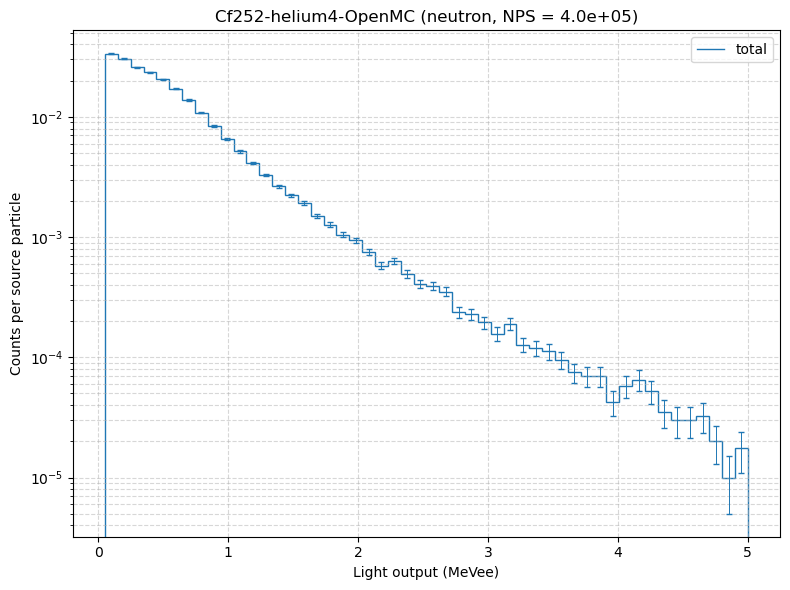

In [5]:
def lo_histogram(lo):
    """Light output histogram normalised per source particle, with Poisson errors."""
    counts, edges = np.histogram(lo, bins=LO_BIN_EDGES)
    norm = NPS * (np.diff(edges) if PER_BIN_WIDTH else 1.0)
    return {"bin_edges": edges,
            "bin_centers": 0.5 * (edges[:-1] + edges[1:]),
            "counts": counts,
            "counts_norm": counts / norm,
            "counts_err_norm": np.sqrt(counts) / norm}

# Keep only pulses of the analysed particle
sel = pulses[pulses["ptype"] == PTYPE]

# One histogram per detector (as grouped in detector_cells) plus the total
hists = {f"det{d}": lo_histogram(sel.loc[sel["cell"].isin(cells), "lo"])
         for d, cells in enumerate(DETECTOR_CELLS)}
all_cells = [c for cells in DETECTOR_CELLS for c in cells]
hists["total"] = lo_histogram(sel.loc[sel["cell"].isin(all_cells), "lo"])

for name, h in hists.items():
    print(f"{name:<6}: {h['counts'].sum()} pulses in [0, {LO_MAX}] MeVee")

# --- Plot -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
to_plot = list(hists) if len(DETECTOR_CELLS) > 1 else ["total"]
for name in to_plot:
    h = hists[name]
    step = ax.stairs(h["counts_norm"], h["bin_edges"], label=name)
    mask = h["counts"] > 0          # empty bins are not drawn on a log scale
    ax.errorbar(h["bin_centers"][mask], h["counts_norm"][mask],
                yerr=h["counts_err_norm"][mask], fmt="none",
                ecolor=step.get_edgecolor(), elinewidth=0.7, capsize=2)

ax.set_title(f"{CFG.get('title', '')} ({PARTICLE}, NPS = {NPS:.1e})")
ax.set_xlabel("Light output (MeVee)")
ax.set_ylabel("Counts per source particle" + (" per MeVee" if PER_BIN_WIDTH else ""))
ax.set_yscale("log")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# Step 4: Save

In [6]:
data = dict()

# Total histogram, same keys as before
tot = hists["total"]
data[f"{LABEL}-bin-edges"]       = tot["bin_edges"]
data[f"{LABEL}-bin-centers"]     = tot["bin_centers"]
data[f"{LABEL}-counts-norm"]     = tot["counts_norm"]
data[f"{LABEL}-counts-err-norm"] = tot["counts_err_norm"]

# Per-detector histograms and run information
data[f"{LABEL}-detectors"] = {k: v for k, v in hists.items() if k != "total"}
data[f"{LABEL}-metadata"]  = {"particle": PARTICLE, "nps": NPS,
                              "detector_cells": DETECTOR_CELLS,
                              "per_bin_width": PER_BIN_WIDTH,
                              "input_config": config_path, "pympost_config": CFG}

os.makedirs(SAVE_DIR, exist_ok=True)
save_path = os.path.join(SAVE_DIR, f"{LABEL}_LO_histogram_{PARTICLE}.joblib")
joblib.dump(data, save_path)
print(f"Saved: {save_path}")

Saved: /Users/loren/WORKSPACE/PHOTON/verification-and-validation/3-coupling-OpenMC-MPPost/results/helium4/252Cf/OpenMC_LO_histogram_neutron.joblib
